# 04 — Multi-Layer Networks, Molecular Zoom-In & Measurement Constraints (Steps 6–7)

**Course tools integrated:** Week 2 (Molecular Structure, Modifications & Similarity via RDKit), Week 3 & Week 13 (Network Topology, Hubs, Modules, Cytoscape `.graphml` Export & Knowledge Integration), Week 8 (IIMN Adduct Collapse, High-Resolution Exact Mass & `³⁴S`/`³⁷Cl` Isotope Verification).

## Step 6 — Multi-Layer Network Analysis

We build two complementary biological networks (both exported as Cytoscape-ready `.graphml` files in `results/networks/`):

1. **Omeprazole Biotransformation Mass-Difference Network (`57` IIMN-collapsed unique molecular entities, `82` exact-mass `< 4.5 mDa` chemical edges):** Connects parent Omeprazole (`ID 2828`) and Ufiprazole (`ID 2962`) to downstream microbial products via exact enzymatic mass shifts: sulfoxide reduction (`−O`, `15.9949 Da`), methylation/O-demethylation (`±CH₂`, `14.0157 Da`), redox (`±H₂`, `2.0157 Da`), S-extrusion rearrangements (`−S+O−H₂`), and C–S cleavage (`±C₉H₁₁NO`).
2. **Endogenous Com20 Metabolic Co-Abundance Network (`91` connected annotated endogenous metabolites, `834` Spearman edges `|r| ≥ 0.72, q < 0.001`, `8` modularity communities, `Q = 0.224`):** Identifies central metabolic hubs coordinating Com20's anaerobic growth program (`15-HEDE` degree 47, `LPE 13:0` degree 44, `Phe-C4:0` degree 44, `Indole-3-propionic acid` degree 42, `N-Acetylhistamine` degree 42, `Oleic acid` degree 42) and bridge hubs (`Guanine`, highest betweenness centrality `0.285`).

=== Top 15 Exact-Mass Biotransformation Network Edges (<0.1 mDa accuracy!) ===


,source_id,source_mz,source_name,target_id,target_mz,target_name,transformation,delta_mz,mass_error_mDa,temporal_pearson_r
0,7841,312.0802,Unknown_7841,9575,326.0959,Unknown_9575,Methylation / Demethylation (±CH2),14.0156,0.00,0.945
1,2368,274.0565,Unknown_2368,2678,288.0721,Unknown_2678,Methylation / Demethylation (±CH2),14.0157,0.01,0.996
2,2478,298.1550,Unknown_2478,2497,296.1393,Unknown_2497,Hydrogenation / Dehydrogenation (±H2),-2.0157,0.01,0.834
3,2685,326.1499,Unknown_2685,3605,344.1427,Unknown_3605,S-Extrusion Rearrangement (±S-O+H2),17.9928,0.01,-0.354
4,2719,342.1448,Unknown_2719,4470,328.1292,Unknown_4470,Methylation / Demethylation (±CH2),-14.0157,0.02,0.835
5,2500,344.1426,Unknown_2500,2618,360.1376,Unknown_2618,Sulfoxide Reduction / Oxidation (±O),15.9949,0.02,0.951
6,2685,326.1499,Unknown_2685,2719,342.1448,Unknown_2719,Sulfoxide Reduction / Oxidation (±O),15.9949,0.02,0.861
7,2500,344.1426,Unknown_2500,2962,330.1270,UFIPRAZOLE,Methylation / Demethylation (±CH2),-14.0156,0.02,0.943
8,2368,274.0565,Unknown_2368,2379,288.0721,Unknown_2379,Methylation / Demethylation (±CH2),14.0156,0.03,0.910
9,8031,312.0802,Unknown_8031,9575,326.0959,Unknown_9575,Methylation / Demethylation (±CH2),14.0156,0.03,0.923


=== Top 12 Endogenous Co-Abundance Network Hubs ===


,row_id,compound_name,chemical_class,module,degree,degree_centrality,betweenness_centrality,beta_time,beta_trt,q_time,q_trt
0,9718,Spectral Match to 15-HEDE from NIST14,"Fatty Acids, Oxylipins & Lipids",4,47,0.5222,0.0412,0.745,-0.475,6.809699e-09,0.229704
1,7272,LPE 13:0,"Fatty Acids, Oxylipins & Lipids",2,44,0.4889,0.0062,1.388,-0.916,1.961767e-11,0.108840
2,4191,Candidate Phenylalanine-C4:0 (delta mass:70.0409),N-Acyl Amino Acids,2,44,0.4889,0.0045,0.618,-0.157,1.810701e-17,0.352918
3,4040,NAE 16:4,"Fatty Acids, Oxylipins & Lipids",1,44,0.4889,0.0015,-0.407,0.169,2.255777e-10,0.386573
4,592,2'-O-Methyladenosine,"Nucleosides, Purines & Amines",1,43,0.4778,0.0057,-0.861,0.223,4.092195e-11,0.582145
5,4553,Indole-3-propionic acid,Indoles & Tryptophan Derivatives,2,42,0.4667,0.0087,0.499,-0.603,2.191151e-12,0.001201
6,167,N-Acetylhistamine,"Nucleosides, Purines & Amines",1,42,0.4667,0.0082,0.880,-0.094,1.670892e-17,0.724724
7,9772,oleic acid,"Fatty Acids, Oxylipins & Lipids",1,42,0.4667,0.0062,-0.711,0.014,5.192413e-12,0.968239
8,6645,3-phenyl-2-pyrrolylpropanoic acid CollisionEne...,Other Annotated Metabolites,1,41,0.4556,0.0519,0.107,0.053,4.068969e-09,0.354286
9,1294,Spectral Match to Phe-Pro from NIST14,Amino Acids & Linear Peptides,1,41,0.4556,0.0100,-0.722,-0.207,1.596858e-08,0.637033


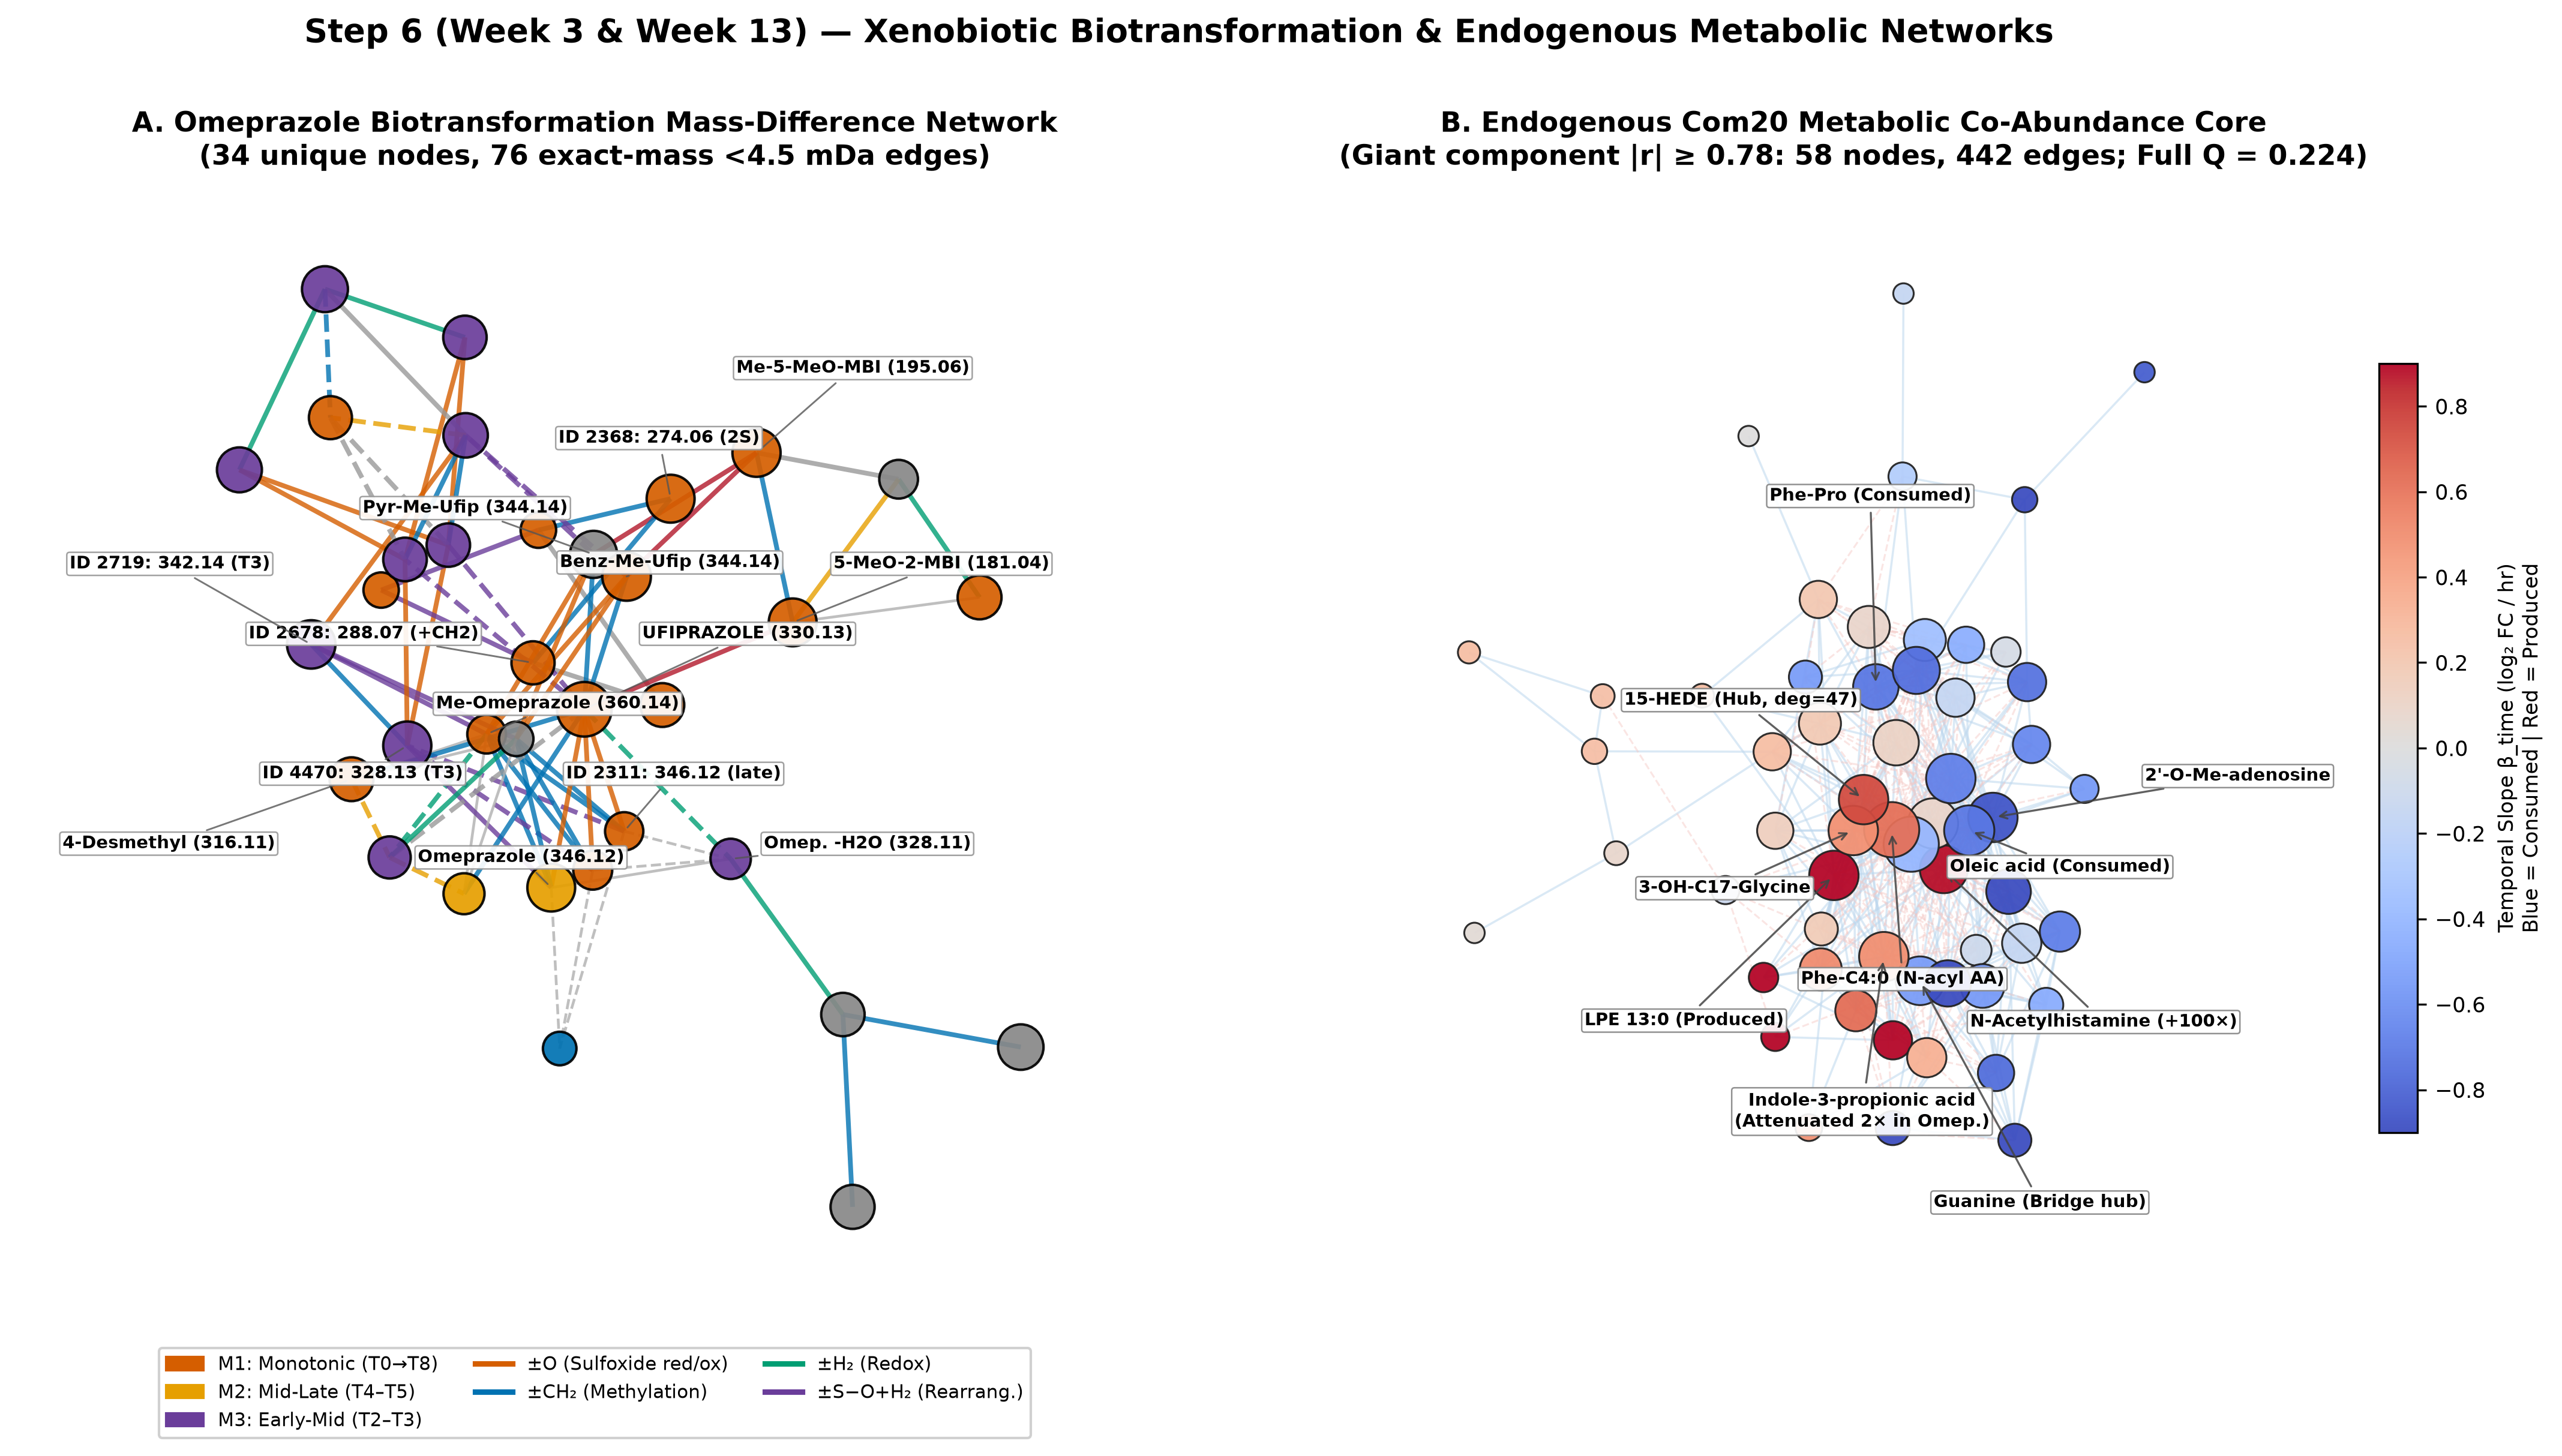

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd().resolve()
if not (ROOT / "data" / "processed").exists():
    ROOT = ROOT.parent

TABLES = ROOT / "results" / "tables"
FIGS = ROOT / "results" / "figures"

t3 = pd.read_csv(TABLES / "table03_top_omeprazole_biotransformation_hits.csv", index_col="row_id")
t6 = pd.read_csv(TABLES / "table06_network_nodes_and_hubs.csv")
t7 = pd.read_csv(TABLES / "table07_biotransformation_edges.csv")

print("=== Top 15 Exact-Mass Biotransformation Network Edges (<0.1 mDa accuracy!) ===")
display(t7.head(15))
print("=== Top 12 Endogenous Co-Abundance Network Hubs ===")
display(t6.head(12))
display(Image(filename=str(FIGS / "fig08_biotransformation_and_coabundance_networks.png"), width=1050))

## Step 7 — Molecular Zoom-In on Key Biotransformation Hits

### Hit 1 — Anaerobic Sulfoxide Reduction & Multi-Step Cascade Around Ufiprazole (`ID 2962`)
- **IIMN Feature Multiplicity:** One single molecule—**Ufiprazole / Omeprazole sulfide (`ID 2962`, `m/z 330.1270`, `RT 1.90 min`, `C₁₇H₁₉N₃O₂S`, GNPS score `0.885`)**—spawns **10 distinct LC-MS features** in `correlation group 220` (`[M+H]+`, `¹³C`, `³⁴S`, `[M+Na]+`, `[M+2H]²⁺`, `[2M+Na]+`, plus massive in-source benzimidazole-S `180.0352` and pyridine `151.0992` fragments), accounting for **~47% of total sample TIC** at T8 (`~9.3 × 10⁸` peak area) and surging **9-fold** (`5.4×10⁷ → 4.9×10⁸`, `r_time = +0.976`). This mirrors classic anaerobic bacterial sulfoxide reductase activity (Watanabe et al., 1995).
- **Downstream Branching Cascade:**
  1. **O-Demethylation (`−CH₂`):** **`ID 2465`** (`Omeprazole 4-desmethylthioether`, `m/z 316.1113`, `C₁₆H₁₇N₃O₂S`, GNPS score `0.869`, `r_time = +0.88`).
  2. **C–S Thioether Cleavage:** **`ID 2480`** (`5-Methoxy-2-mercaptobenzimidazole`, `CAS 37052-78-1`, `m/z 181.0430`, `C₈H₈N₂OS`, GNPS score `0.894`, `³⁴S M+2 = 4.2%` confirming `1S`, rising 25× from T0→T7) -> further methylated to **`ID 1677`** (`m/z 195.0588`, `C₉H₁₀N₂OS`, `+0.5 ppm`, confirmed by co-eluting `−•CH₃` fragment `180.0351` in `cg=107`).
  3. **Regioselective Methylation Proven by Co-Eluting In-Source Fragments (`+CH₂`, `m/z 344.1427`, `C₁₈H₂₁N₃O₂S`, `0.0 ppm`):**
     - **`ID 3605` (`RT 2.17 min, cg=264`):** Co-elutes with `194.0510` (**+CH₂ on benzimidazole-S**) + `151.0991` (**unmodified pyridine**) → **Benzimidazole-methylated ufiprazole**.
     - **`ID 2500` (`RT 1.55 min, cg=175`):** Co-elutes with `180.0353` (**unmodified benzimidazole-S**) + `165.1147` (**+CH₂ on pyridine**) → **Pyridine-methylated ufiprazole**.
  4. **High-Confidence Unannotated Dark-Metabolome Hit — `ID 2368` (`m/z 274.0565`, `RT 1.43 min`, +95× T0→T8, `r_time = +0.975`):**
     - Exhibits an **`8.2%` `³⁴S` M+2 isotope peak (`ID 2369`, `Δ = +1.9952 Da`, `r = 0.99`)** proving **2 sulfur atoms** (`~1.9 S`), plus co-eluting **`ID 2370` (`m/z 151.0992`)** proving an **intact omeprazole pyridine moiety (`C₉H₁₂NO`)**.
     - Unique exact-mass formula: **`C₁₁H₁₅NO₃S₂` (`−0.46 ppm`, `RDB = 5`)**, accompanied by a methylated analog **`ID 2678` (`m/z 288.0722`, `Δ = +14.0157 Da`, `0.01 mDa` error, `r = 0.996`)**. Chemically consistent with a **pyridine-methyl + thioglycolate mixed disulfide** (thioglycolate is the anaerobic reducing agent in mGAM medium, echoing omeprazole's known covalent disulfide reactivity!). *(Separated clearly as a structural hypothesis awaiting MS2/standard confirmation.)*

=== Top 18 Unique Omeprazole Biotransformation Hits (Exact-Mass Formulas & 34S Evidence) ===


,mz,rt,max_omepr_pqn,spearman_time_omepr,peak_tp_omepr,kinetic_module,compound_name,putative_formula,formula_ppm_error,isotope_evidence
row_id,,,,,,,,,,
2962,330.126999,1.897611,5.637644e+08,0.975645,T8,M1: Monotonic Accumulation (T0->T8),UFIPRAZOLE,C17H19N3O2S,0.00,No M+2 (low signal or 0-1 S)
3605,344.142732,2.174564,2.717612e+07,0.746628,T4,M1: Monotonic Accumulation (T0->T8),NaN,C18H21N3O2S1,0.02,No M+2 (low signal or 0-1 S)
2719,342.144840,1.683526,2.525918e+07,-0.315286,T3,M3: Early-Mid Intermediates (Peak T2-T3),NaN,C18H19N3O4,0.02,No M+2 (low signal or 0-1 S)
1677,195.058765,0.919622,2.259929e+07,0.731154,T4,M1: Monotonic Accumulation (T0->T8),NaN,C9H10N2O1S1,0.53,No M+2 (low signal or 0-1 S)
4470,328.129171,2.555013,2.211053e+07,-0.369058,T3,M3: Early-Mid Intermediates (Peak T2-T3),NaN,C17H17N3O4,-0.03,No M+2 (low signal or 0-1 S)
2368,274.056485,1.426299,1.992886e+07,0.975258,T8,M1: Monotonic Accumulation (T0->T8),NaN,C11H15N1O3S2,-0.46,"34S M+2 confirmed (ID 2369, 8.2% ~ 1.9S, r=1.00)"
2480,181.043035,1.523150,1.907525e+07,0.882800,T6,M1: Monotonic Accumulation (T0->T8),37052-78-1,C8H8N2OS,0.00,"34S M+2 confirmed (ID 2479, 4.2% ~ 1.0S, r=1.00)"
2828,346.121767,1.777913,1.863183e+07,0.077507,T4,M2: Mid-Late Transients (Peak T4-T5),omeprazole,C17H19N3O3S,0.00,No M+2 (low signal or 0-1 S)
2478,298.154978,1.522623,8.160072e+06,-0.438692,T3,M3: Early-Mid Intermediates (Peak T2-T3),NaN,C17H19N3O2,-0.09,No M+2 (low signal or 0-1 S)


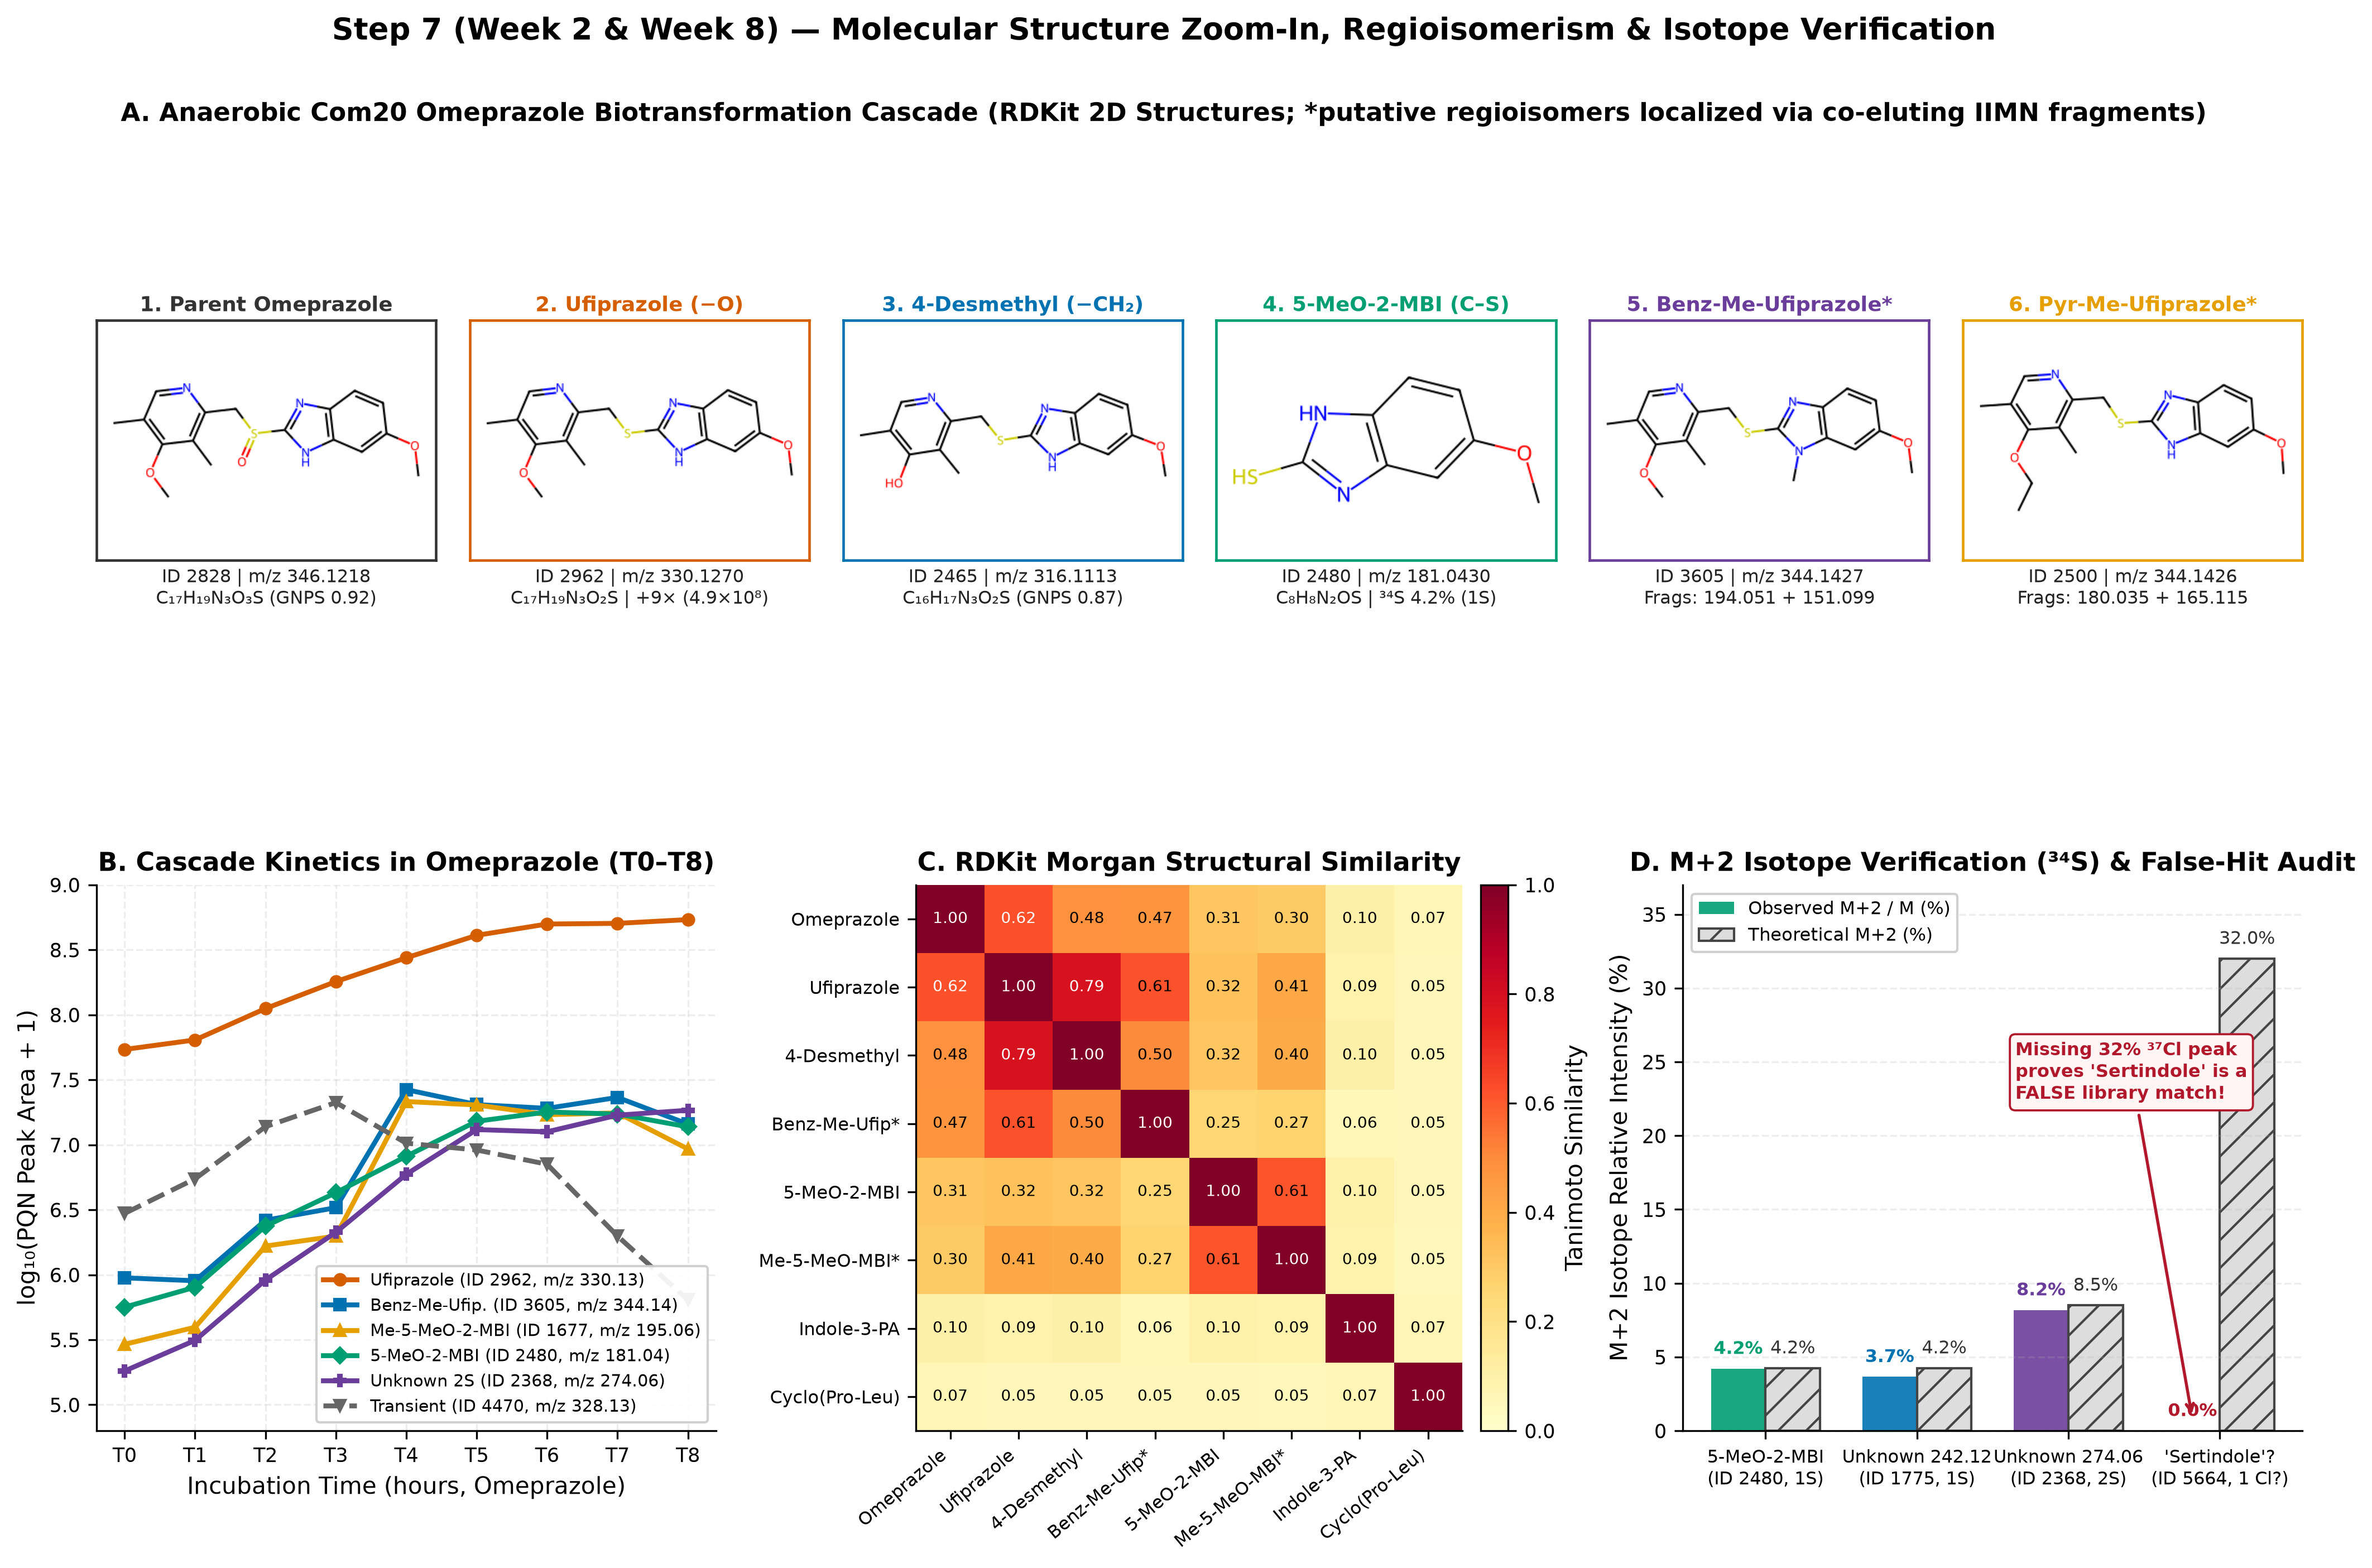

In [2]:
print("=== Top 18 Unique Omeprazole Biotransformation Hits (Exact-Mass Formulas & 34S Evidence) ===")
display(t3[["mz", "rt", "max_omepr_pqn", "spearman_time_omepr", "peak_tp_omepr", "kinetic_module", "compound_name", "putative_formula", "formula_ppm_error", "isotope_evidence"]].head(18))
display(Image(filename=str(FIGS / "fig09_hit_zoomin_structures_and_regioisomers.png"), width=1050))

## Synthesis of Measurement Constraints & Analytical Limitations

| Constraint | What We Observed in ME2 | How It Limits Conclusions / How We Mitigated It |
| --- | --- | --- |
| **Positive-mode ESI & EtOAc extraction** | Captures basic/neutral N-heterocycles (prazoles, indoles, DKPs, acyl-AAs) well; blind to acidic SCFAs (acetate, propionate, butyrate) and polar phosphorylated central-carbon intermediates. | Cannot rule out omeprazole effects on anaerobic SCFA fermentation or glycolysis without negative-mode/HILIC/GC-MS data. |
| **Ionization efficiency ≠ molar concentration** | Ufiprazole (`cg=220`) reaches ~47% of total TIC, doubling late Omeprazole TIC. | Peak areas are semi-quantitative relative intensities; mitigated compositional distortion via **PQN** instead of TIC normalization. |
| **ESI co-elution ion suppression** | `66.3%` (`114/172`, `OR = 46.5, p = 2.1×10⁻⁹¹`) of negative shared interactions cluster inside `RT 1.80–2.25 min` under Ufiprazole's `4.9×10⁸` peak. | Flagged `RT 1.80–2.25 min` so suppressed endogenous features (e.g., `N-Phenethylacetamide ID 2972`) are not mistaken for biological depletion. |
| **Autosampler instability & run-order confounding** | Timepoint correlates with `run_date` (`r = -0.45`); acid-labile parent Omeprazole (`ID 2828`) decays over the 5.3-day queue (`r = -0.62`), hitting `0` at T1/T2. | Adjusted linear models for `run_hours` and verified stable biotransformation kinetics independently of queue order; parent decay cannot be quantified naively from `ID 2828`. |
| **No abiotic Omeprazole + mGAM time-series control in this subset** | Only `T0_Medium_noBac` (`n = 3`, no omeprazole) is included in this subset table. | Spontaneous chemical degradation vs enzymatic bacterial conversion cannot be strictly separated from this CSV alone (though Pakkir Shah et al. confirm microbial enrichment vs abiotic controls). |
| **Dark metabolome (92.4% unannotated) & library false hits** | Only `259/3,414` filtered features have library matches; `ID 5664` (`Sertindole`) lacks its required `32% ³⁷Cl` peak. | Retained and ranked unannotated features via ML + exact mass + `³⁴S` isotopes + IIMN fragments; audited library hits chemically rather than accepting names blindly. |
| **Small sample size (`n = 2–3` per cell) & 4 failed injections** | Removing 4 blank-like T4/T5 injections reduces T4 & T5 to `n = 2` per treatment. | Limits power for subtle endogenous perturbations; cross-checked findings with continuous time models, categorical ANOVA, PERMANOVA, and replicate-consistency metrics. |